In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(r"data\WA_Fn-UseC_-HR-Employee-Attrition.csv")

before = {
    "rows": len(df),
    "missing_values": int(df.isna().sum().sum()),
    "duplicates": int(df.duplicated().sum()),
}
print(before)
df.info()

{'rows': 1470, 'missing_values': 0, 'duplicates': 0}
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14

In [2]:

print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
print("Total missing:", df.isna().sum().sum())


print("\nConstant columns:")
print([c for c in df.columns if df[c].nunique() == 1])


text_cols = df.select_dtypes(exclude="number").columns
print("\nText columns:")
for c in text_cols:
    print(c, "->", df[c].unique())

Missing values per column:
Series([], dtype: int64)
Total missing: 0

Constant columns:
['EmployeeCount', 'Over18', 'StandardHours']

Text columns:
Attrition -> <StringArray>
['Yes', 'No']
Length: 2, dtype: str
BusinessTravel -> <StringArray>
['Travel_Rarely', 'Travel_Frequently', 'Non-Travel']
Length: 3, dtype: str
Department -> <StringArray>
['Sales', 'Research & Development', 'Human Resources']
Length: 3, dtype: str
EducationField -> <StringArray>
[   'Life Sciences',            'Other',          'Medical',
        'Marketing', 'Technical Degree',  'Human Resources']
Length: 6, dtype: str
Gender -> <StringArray>
['Female', 'Male']
Length: 2, dtype: str
JobRole -> <StringArray>
[          'Sales Executive',        'Research Scientist',
     'Laboratory Technician',    'Manufacturing Director',
 'Healthcare Representative',                   'Manager',
      'Sales Representative',         'Research Director',
           'Human Resources']
Length: 9, dtype: str
MaritalStatus -> <Strin

In [3]:

print("Duplicates found:", df.duplicated().sum())
df = df.drop_duplicates()


text_cols = df.select_dtypes(exclude="number").columns
for c in text_cols:
    df[c] = df[c].str.strip()


const_cols = [c for c in df.columns if df[c].nunique() == 1]
df = df.drop(columns=const_cols)
print("Dropped constant columns:", const_cols)


cat_cols = df.select_dtypes(exclude="number").columns
df[cat_cols] = df[cat_cols].astype("category")
print("Converted to category:", list(cat_cols))

print("\nShape now:", df.shape)


Duplicates found: 0
Dropped constant columns: ['EmployeeCount', 'Over18', 'StandardHours']
Converted to category: ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Shape now: (1470, 32)


                    column  lower_limit  upper_limit  outliers
0                      Age         10.5         62.5         0
1            MonthlyIncome      -5291.0      16581.0       114
2        TotalWorkingYears         -7.5         28.5        63
3           YearsAtCompany         -6.0         18.0       104
4       YearsInCurrentRole         -5.5         14.5        21
5  YearsSinceLastPromotion         -4.5          7.5       107
6     YearsWithCurrManager         -5.5         14.5        14
7       NumCompaniesWorked         -3.5          8.5        52
8    TrainingTimesLastYear          0.5          4.5       238


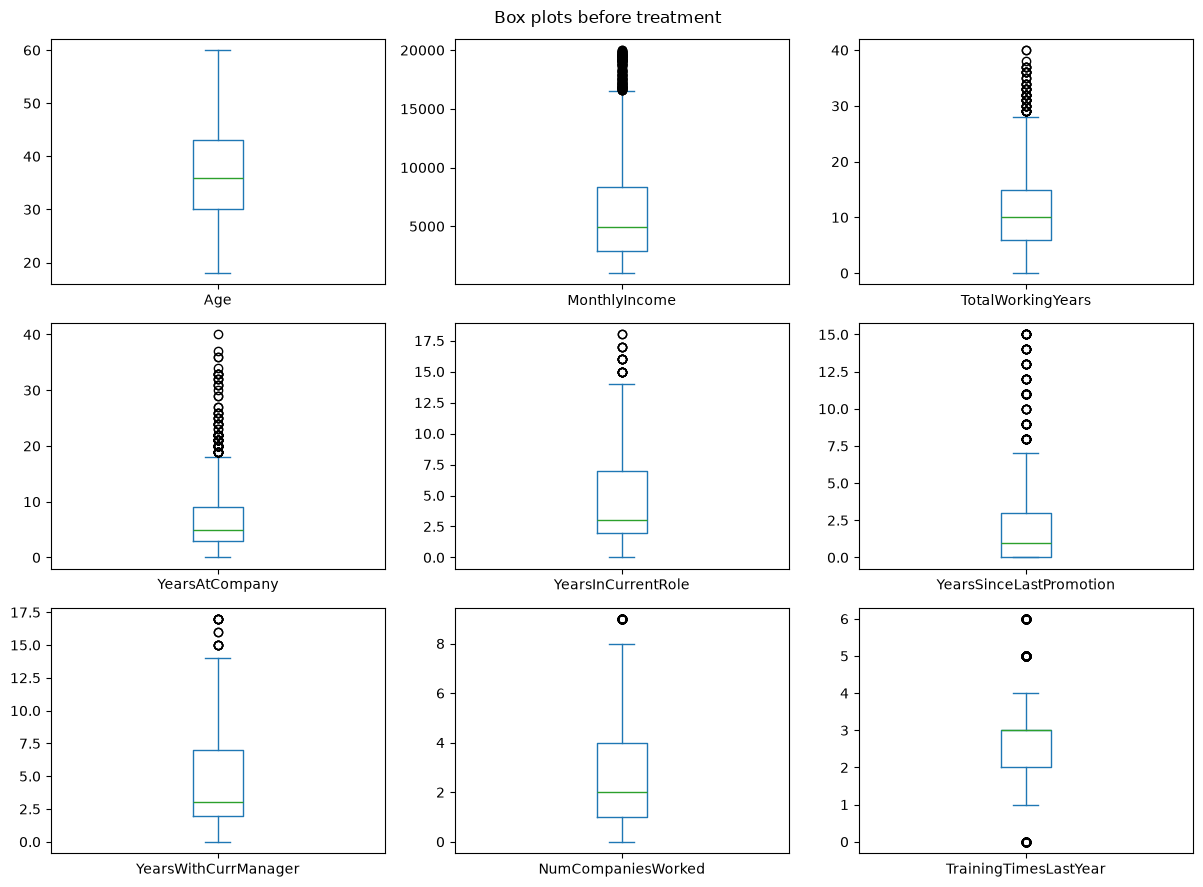

In [4]:

num_cols = ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany",
            "YearsInCurrentRole", "YearsSinceLastPromotion", "YearsWithCurrManager",
            "NumCompaniesWorked", "TrainingTimesLastYear"]

outlier_summary = []
for c in num_cols:
    q1, q3 = df[c].quantile(0.25), df[c].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[c] < lower) | (df[c] > upper)).sum()
    outlier_summary.append([c, lower, upper, n_out])

outlier_df = pd.DataFrame(outlier_summary,
                          columns=["column", "lower_limit", "upper_limit", "outliers"])
print(outlier_df)


df[num_cols].plot(kind="box", subplots=True, layout=(3, 3),
                  figsize=(12, 9), title="Box plots before treatment")
plt.tight_layout()
plt.show()

In [5]:

for c in ["MonthlyIncome", "YearsAtCompany"]:
    q1, q3 = df[c].quantile(0.25), df[c].quantile(0.75)
    iqr = q3 - q1
    df[c + "_outlier"] = (df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)


after = {
    "rows": len(df),
    "missing_values": int(df.isna().sum().sum()),
    "duplicates": int(df.duplicated().sum()),
}
summary = pd.DataFrame({"Before": before, "After": after})
print(summary)


df.to_csv("clean_data.csv", index=False)
print("\nSaved clean_data.csv")

                Before  After
rows              1470   1470
missing_values       0      0
duplicates           0      0

Saved clean_data.csv




| Step | Finding | Decision |
|------|---------|----------|
| Missing values | 0 in all columns | No drop or fill needed |
| Duplicates | 0 found | Checked and removed (none) |
| Text standardisation | Values already consistent | Trimmed spaces only |
| Constant columns | EmployeeCount, Over18, StandardHours | Dropped: same value in every row, no information |
| Data types | Text columns stored as str | Converted to category |
| Outliers (IQR rule) | Found in YearsAtCompany, YearsInCurrentRole, YearsSinceLastPromotion, YearsWithCurrManager, NumCompaniesWorked, TrainingTimesLastYear | Kept and flagged (MonthlyIncome_outlier, YearsAtCompany_outlier): values are genuine, not errors |

**Result:** Rows 1470 -> 1470 | Missing 0 -> 0 | Duplicates 0 -> 0
(Dataset was already clean; 3 columns dropped, 2 outlier flag columns added.)